# Spacecraft Rendezvous Control

A **chaser** spacecraft must rendezvous with a **target** spacecraft. The two start on **different orbits** around Earth. This project develops the complete simulation and control pipeline:

1. **Linearize** the nonlinear relative dynamics to obtain a state-space model
2. **Analyze** the open-loop system (eigenvalues, stability)
3. **Design** a full-state feedback controller by **pole placement**
4. **Investigate** closed-loop behavior across two experiments (fuel/accuracy trade-off and damping-ratio study)

## State-Space Setup
State (chaser relative to target, expressed in the target's rotating Local Vertical, Local Horizontal (LVLH) frame):
$$\mathbf{x} = [x,\, y,\, z,\, \dot{x},\, \dot{y},\, \dot{z}]^T$$
- $x$: radial (up), $y$: along-track (direction of flight), $z$: cross-track
- Input $\mathbf{u}$: thrust acceleration [m/s²], limited to $|u_i| \le u_{max}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.signal import place_poles
from IPython.display import HTML

plt.rcParams['figure.figsize'] = (10, 6)

# ---- Physical constants ----
mu = 3.986004418e14          # Earth grav. parameter [m^3/s^2]
R_earth = 6371e3             # [m]

# ---- Target orbit (circular) ----
alt_t, inc_t, raan_t, u0_t = 500e3, np.deg2rad(51.6), 0.0, np.deg2rad(0.0)
# ---- Chaser orbit (DIFFERENT altitude, inclination, phase) ----
alt_c, inc_c, raan_c, u0_c = 520e3, np.deg2rad(51.7), 0.0, np.deg2rad(-0.20)

a_t = R_earth + alt_t
n_t = np.sqrt(mu / a_t**3)       # target mean motion [rad/s] -- the "n" in the CW equations
T_orbit = 2*np.pi / n_t

def Rz(th):
    return np.array([[np.cos(th), -np.sin(th), 0],
                     [np.sin(th),  np.cos(th), 0], [0, 0, 1]])
def Rx(th):
    return np.array([[1, 0, 0], [0, np.cos(th), -np.sin(th)],
                     [0, np.sin(th),  np.cos(th)]])

def circular_orbit_state(alt, inc, raan, u0):
    r = R_earth + alt
    v = np.sqrt(mu / r)
    R = Rz(raan) @ Rx(inc)
    r_eci = R @ np.array([r*np.cos(u0), r*np.sin(u0), 0.0])
    v_eci = R @ np.array([-v*np.sin(u0), v*np.cos(u0), 0.0])
    return r_eci, v_eci

r_t0, v_t0 = circular_orbit_state(alt_t, inc_t, raan_t, u0_t)
r_c0, v_c0 = circular_orbit_state(alt_c, inc_c, raan_c, u0_c)

# ---- Simulation timing ----
T_rdv = 3000.0   # rendezvous duration [s]
dt = 0.5
u_max_default = 0.5   # thruster limit [m/s^2]

print(f"n = {n_t:.6e} rad/s | orbital period = {T_orbit/60:.1f} min")
print(f"Initial separation: {np.linalg.norm(r_c0-r_t0)/1e3:.2f} km")

n = 1.108508e-03 rad/s | orbital period = 94.5 min
Initial separation: 31.26 km


# Part 1: Linearization

The exact nonlinear relative dynamics in the target's LVLH frame are:

$$\ddot{x} = 2n\dot{y} + n^2 x - \frac{\mu (r_t + x)}{\rho^3} + \frac{\mu}{r_t^2} + u_x$$
$$\ddot{y} = -2n\dot{x} + n^2 y - \frac{\mu y}{\rho^3} + u_y$$
$$\ddot{z} = -\frac{\mu z}{\rho^3} + u_z, \qquad \rho = \sqrt{(r_t+x)^2 + y^2 + z^2}$$

Linearizing about the equilibrium $\mathbf{x}^* = \mathbf{0}$, $\mathbf{u}^* = \mathbf{0}$ (chaser coincident with target) yields the classical **Clohessy–Wiltshire (CW) equations**. The Jacobians $A = \partial f/\partial \mathbf{x}$ and $B = \partial f/\partial \mathbf{u}$ evaluated at the equilibrium give the state-space model

$$\dot{\mathbf{x}} = A\mathbf{x} + B\mathbf{u}.$$

The key derivative in the expansion,
$\frac{\partial}{\partial x}\left[\frac{\mu(r_t+x)}{\rho^3}\right]_{\mathbf{0}} = -2\mu/r_t^3 = -2n^2$,
produces the $+3n^2$ radial-stiffness term.

Below, the analytic $A$ and $B$ are populated and then verified against a finite-difference Jacobian of the full nonlinear dynamics; the max element-wise error should be well below $10^{-6}$.

In [2]:
# Exact nonlinear relative dynamics in the target's LVLH frame
def f_nonlinear_relative(x_state, u):
    x, y, z, vx, vy, vz = x_state
    rho = np.sqrt((a_t + x)**2 + y**2 + z**2)
    ax = 2*n_t*vy + n_t**2*x - mu*(a_t + x)/rho**3 + mu/a_t**2 + u[0]
    ay = -2*n_t*vx + n_t**2*y - mu*y/rho**3 + u[1]
    az = -mu*z/rho**3 + u[2]
    return np.array([vx, vy, vz, ax, ay, az])

# ----------------------------------------------------------------
# Analytic Clohessy-Wiltshire A (6x6) and B (6x3) matrices.
# State ordering: x = [x, y, z, xdot, ydot, zdot]
# ----------------------------------------------------------------
n = n_t  # mean motion

A = np.zeros((6, 6))
# top-right identity block (position derivatives = velocities)
A[0, 3] = 1.0
A[1, 4] = 1.0
A[2, 5] = 1.0
# acceleration rows (Clohessy-Wiltshire)
A[3, 0] =  3 * n**2   # radial stiffness
A[3, 4] =  2 * n      # Coriolis: y-vel -> x-accel
A[4, 3] = -2 * n      # Coriolis: x-vel -> y-accel
A[5, 2] = -n**2       # cross-track stiffness

B = np.zeros((6, 3))
B[3, 0] = 1.0
B[4, 1] = 1.0
B[5, 2] = 1.0

# ----------------------------------------------------------------
# Verification against a finite-difference Jacobian of the full
# nonlinear dynamics. Both errors should print < 1e-6.
# ----------------------------------------------------------------
eps = 1e-3
A_check, B_check = np.zeros((6, 6)), np.zeros((6, 3))
for j in range(6):
    d = np.zeros(6); d[j] = eps
    A_check[:, j] = (f_nonlinear_relative(d, np.zeros(3)) -
                     f_nonlinear_relative(-d, np.zeros(3))) / (2*eps)
for j in range(3):
    d = np.zeros(3); d[j] = eps
    B_check[:, j] = (f_nonlinear_relative(np.zeros(6), d) -
                     f_nonlinear_relative(np.zeros(6), -d)) / (2*eps)

errA, errB = np.abs(A - A_check).max(), np.abs(B - B_check).max()
print(f"max|A_analytic - A_numerical| = {errA:.2e}  {'PASS' if errA < 1e-6 else 'FAIL'}")
print(f"max|B_analytic - B_numerical| = {errB:.2e}  {'PASS' if errB < 1e-6 else 'FAIL'}")

max|A_analytic - A_numerical| = 7.63e-13  PASS
max|B_analytic - B_numerical| = 0.00e+00  PASS


In [3]:
# ---- LVLH frame construction and relative-state transformation ----
def lvlh_frame(r_t, v_t):
    x_hat = r_t / np.linalg.norm(r_t)
    h = np.cross(r_t, v_t)
    z_hat = h / np.linalg.norm(h)
    y_hat = np.cross(z_hat, x_hat)
    R = np.vstack([x_hat, y_hat, z_hat])
    omega_eci = h / np.dot(r_t, r_t)
    return R, omega_eci

def relative_state_lvlh(r_t, v_t, r_c, v_c):
    R, omega_eci = lvlh_frame(r_t, v_t)
    rho = R @ (r_c - r_t)
    rho_dot = R @ (v_c - v_t) - np.cross(R @ omega_eci, rho)
    return rho, rho_dot, R

rho0, rho_dot0, _ = relative_state_lvlh(r_t0, v_t0, r_c0, v_c0)
print("Initial LVLH position [m]:  ", np.round(rho0, 1))
print("Initial LVLH velocity [m/s]:", np.round(rho_dot0, 3))

# ---- Smooth (quintic) reference trajectory from initial relative state to the origin ----
# The quintic polynomial matches position, velocity, and acceleration at both endpoints,
# giving a jerk-free reference for the tracking controller to follow.
def quintic_coeffs(p0, v0, a0, pf, vf, af, T):
    M = np.array([[1,0,0,0,0,0],[0,1,0,0,0,0],[0,0,2,0,0,0],
                  [1,T,T**2,T**3,T**4,T**5],
                  [0,1,2*T,3*T**2,4*T**3,5*T**4],
                  [0,0,2,6*T,12*T**2,20*T**3]])
    return np.linalg.solve(M, np.array([p0,v0,a0,pf,vf,af]))

def eval_quintic(c, t):
    p = c[0]+c[1]*t+c[2]*t**2+c[3]*t**3+c[4]*t**4+c[5]*t**5
    v = c[1]+2*c[2]*t+3*c[3]*t**2+4*c[4]*t**3+5*c[5]*t**4
    a = 2*c[2]+6*c[3]*t+12*c[4]*t**2+20*c[5]*t**3
    return p, v, a

def make_desired(T_traj):
    cf = [quintic_coeffs(rho0[i], rho_dot0[i], 0, 0, 0, 0, T_traj) for i in range(3)]
    def desired_state(t):
        t = np.clip(t, 0, T_traj)
        pd, vd, ad = np.zeros(3), np.zeros(3), np.zeros(3)
        for i in range(3):
            pd[i], vd[i], ad[i] = eval_quintic(cf[i], t)
        if t >= T_traj:
            vd[:] = 0; ad[:] = 0
        return pd, vd, ad
    return desired_state

Initial LVLH position [m]:   [ 19958. -24054.    -42.]
Initial LVLH velocity [m/s]: [ -0.116 -33.242  13.274]


In [4]:
# ================================================================
# Full nonlinear truth simulator (RK4 integration in the ECI frame).
#   K        : 3x6 state feedback gain (use np.zeros((3,6)) for open loop)
#   T_traj   : rendezvous duration for the reference trajectory
#   T_end    : total simulated time (set > T_traj to watch post-arrival settling)
#   u_max    : per-axis thrust limit
#   dist     : constant unmodeled disturbance accel on the chaser, LVLH [m/s^2]
# ================================================================
def gravity(r): return -mu * r / np.linalg.norm(r)**3

def run_sim(K, use_ff=False, T_traj=T_rdv, T_end=None, u_max=u_max_default,
            dist=np.zeros(3)):
    T_end = T_traj if T_end is None else T_end
    des = make_desired(T_traj)
    ts = np.arange(0, T_end + dt, dt)
    Nl = len(ts)
    S = np.concatenate([r_t0, v_t0, r_c0, v_c0])
    out = {nm: np.zeros((Nl, 3)) for nm in ['rho','rhod','Pd','E','U','Rt','Rc']}
    out['t'] = ts

    def dyn(S, u_eci, d_eci):
        r_t, v_t, r_c, v_c = S[0:3], S[3:6], S[6:9], S[9:12]
        return np.concatenate([v_t, gravity(r_t),
                               v_c, gravity(r_c) + u_eci + d_eci])

    for k, t in enumerate(ts):
        r_t, v_t, r_c, v_c = S[0:3], S[3:6], S[6:9], S[9:12]
        rho, rho_dot, R_e2l = relative_state_lvlh(r_t, v_t, r_c, v_c)
        pd, vd, ad = des(t)
        x, x_d = np.concatenate([rho, rho_dot]), np.concatenate([pd, vd])

        u_ff = u_feedforward(pd, vd, ad) if use_ff else np.zeros(3)
        u_lvlh = np.clip(u_ff + K @ (x_d - x), -u_max, u_max)
        u_eci  = R_e2l.T @ u_lvlh
        d_eci  = R_e2l.T @ dist

        out['rho'][k], out['rhod'][k] = rho, rho_dot
        out['Pd'][k], out['E'][k], out['U'][k] = pd, pd - rho, u_lvlh
        out['Rt'][k], out['Rc'][k] = r_t, r_c

        k1 = dyn(S, u_eci, d_eci); k2 = dyn(S + 0.5*dt*k1, u_eci, d_eci)
        k3 = dyn(S + 0.5*dt*k2, u_eci, d_eci); k4 = dyn(S + dt*k3, u_eci, d_eci)
        S = S + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    out['dv'] = np.sum(np.linalg.norm(out['U'], axis=1)) * dt
    out['max_err'] = np.linalg.norm(out['E'], axis=1).max()
    out['final_err'] = np.linalg.norm(out['E'][-1])
    out['final_speed'] = np.linalg.norm(out['rhod'][-1])
    out['peak_u'] = np.abs(out['U']).max()
    return out

# Standard three-axis tracking plot
def plot_run(res, title=''):
    labels = ['x radial','y along-track','z cross-track']
    fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    for i in range(3):
        axs[i].plot(res['t'], res['Pd'][:, i], 'k--', label='Desired')
        axs[i].plot(res['t'], res['rho'][:, i], 'g-', label='Actual')
        axs[i].set_ylabel(labels[i]+' [m]'); axs[i].grid(True); axs[i].legend()
    axs[0].set_title(title); axs[2].set_xlabel('Time [s]')
    plt.tight_layout(); plt.show()

def report(res, name):
    print(f"{name:<35} max_err={res['max_err']:9.2f} m | final_err={res['final_err']:8.3f} m | "
          f"final_speed={res['final_speed']:.4f} m/s | dV={res['dv']:6.1f} m/s | peak_u={res['peak_u']:.4f}")

In [5]:
# ----------------------------------------------------------------
# Feedforward acceleration derived from the CW model: given a
# reference (pd, vd, ad), u_ff makes x_d(t) an exact solution of
# xdot = A x + B u, so the closed-loop error obeys edot = (A-BK)e.
# Derivation: solve the bottom 3 rows of xdot_d = A x_d + B u_ff
# for u_ff, using the known reference acceleration a_d.
# ----------------------------------------------------------------
def u_feedforward(pd, vd, ad):
    n = n_t
    ux = ad[0] - 3*n**2*pd[0] - 2*n*vd[1]
    uy = ad[1]                + 2*n*vd[0]
    uz = ad[2] +   n**2*pd[2]
    return np.array([ux, uy, uz])

# Part 2: Open-Loop Analysis

Before designing a controller, it is important to characterize the uncontrolled plant.

**Eigenvalue analysis.** The six eigenvalues of $A$ characterize the natural modes of the linearized relative motion. Their placement (on the imaginary axis vs. in the right/left half-plane) determines whether the open-loop system is asymptotically stable, marginally stable, or unstable.

**Uncontrolled simulation.** Running the truth simulator with zero thrust over one full orbital period shows the natural drift between the chaser and target caused by their differing orbits.

Together, these two results motivate why active feedback control is required: the natural dynamics alone will not bring the chaser to the target.

[ 0.+0.j        0.+0.j       -0.+0.001109j -0.-0.001109j  0.+0.001109j
  0.-0.001109j]


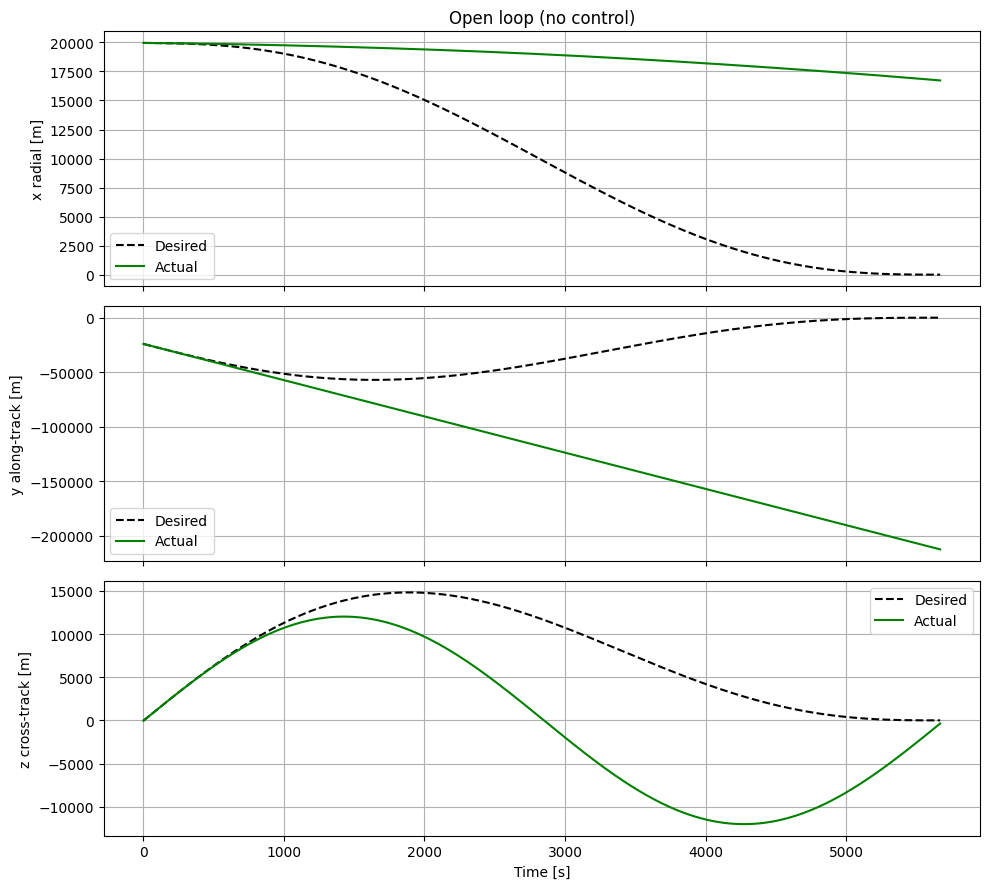

In [6]:
# ---- Open-loop eigenvalues of A ----
eigs = np.linalg.eigvals(A)
print(np.round(eigs, 6))

# ---- Uncontrolled truth simulation over one orbital period ----
# Zero gain, no feedforward: the chaser coasts under gravity alone.
res_ol = run_sim(K=np.zeros((3, 6)), use_ff=False, T_traj=T_orbit, T_end=T_orbit)
plot_run(res_ol, 'Open loop (no control)')

# Part 3: Pole Placement

A full-state feedback law $\mathbf{u} = K(\mathbf{x}_d - \mathbf{x})$ produces the closed-loop error dynamics

$$\dot{\mathbf{e}} = (A - BK)\,\mathbf{e}.$$

Choosing the six eigenvalues of $(A - BK)$ specifies the desired transient behavior; `scipy.signal.place_poles` returns the $K$ that realizes them.

**Design considerations driving pole selection:**

1. **Settling time.** With the dominant pole at $\lambda_{min}$, the error settles in roughly $T_s \approx 4/|\text{Re}(\lambda_{min})|$. This should be well below the rendezvous window $T_{rdv} = 3000$ s (a factor of 5–10× faster is a reasonable target). $T_{rdv}$ is the time allocated for the chaser to complete its trajectory and reach the target.
2. **Actuator authority.** A position error of $e_0$ meters demands feedback thrust on the order of $|\lambda|^2 e_0$. With initial errors of several km, poles must stay slow enough to keep peak thrust below $u_{max} = 0.5$ m/s².
3. **Distinct poles.** `place_poles` requires six distinct eigenvalues.

The pole set below places all six eigenvalues on the negative real axis (no oscillation), spread between $-0.0085$ and $-0.0125$ rad/s. This gives a dominant time constant of roughly $1/0.0085 \approx 118$ s and a settling time of about $470$ s — comfortably faster than the 3000 s rendezvous horizon while keeping commanded thrust within limits.

Achieved closed-loop eigenvalues:
[-0.0125 -0.011  -0.01   -0.0085 -0.012  -0.009 ]


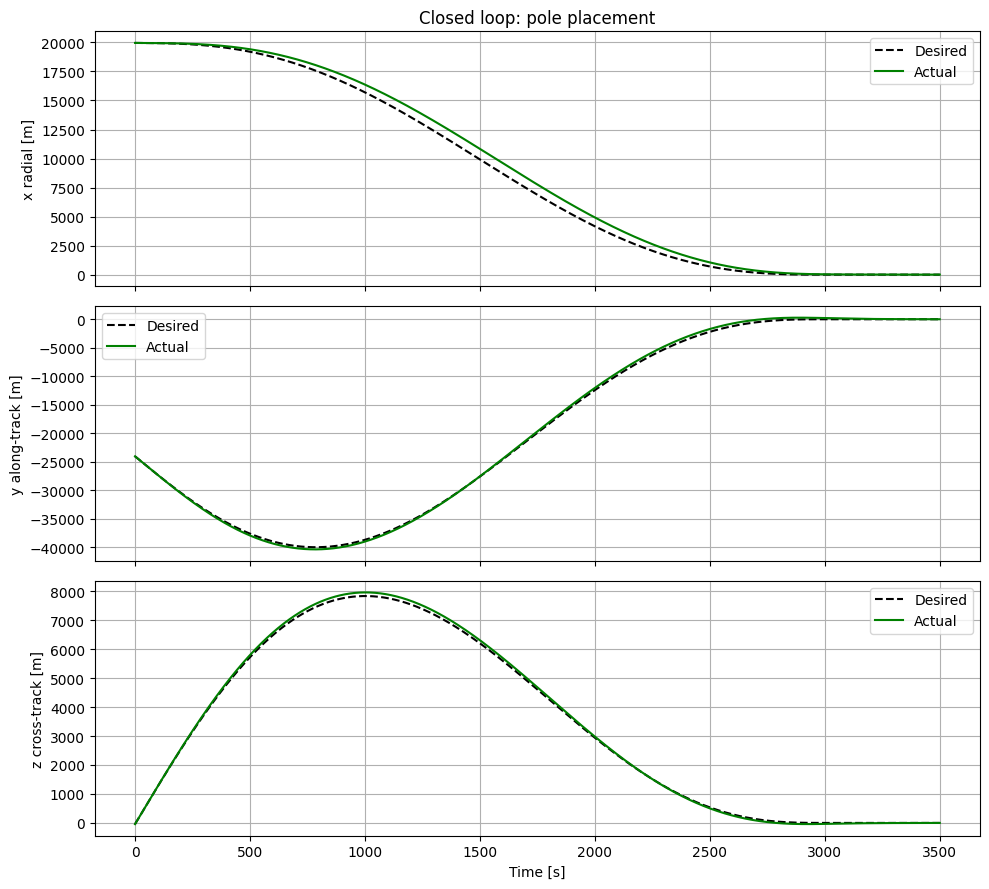

Nominal design                      max_err=   922.46 m | final_err=   5.331 m | final_speed=0.0445 m/s | dV= 218.4 m/s | peak_u=0.1114


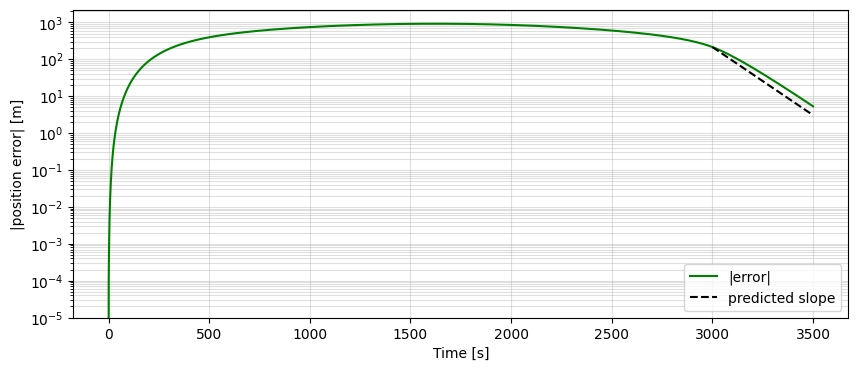

In [7]:
# ----------------------------------------------------------------
# Six distinct negative-real closed-loop poles.
# Dominant pole at -0.0085 rad/s -> settling time ~ 470 s << T_rdv.
# ----------------------------------------------------------------
desired_poles = np.array([
    -0.0085,
    -0.0090,
    -0.0100,
    -0.0110,
    -0.0120,
    -0.0125
])

K = place_poles(A, B, desired_poles).gain_matrix
print("Achieved closed-loop eigenvalues:")
print(np.round(np.linalg.eigvals(A - B @ K), 5))


# Closed-loop truth simulation (extended past T_rdv to see the tail settle)
res_nominal = run_sim(K, use_ff=False, T_end=T_rdv + 500)
plot_run(res_nominal, 'Closed loop: pole placement')
report(res_nominal, 'Nominal design')


# Log-scale error plot: after the reference finishes at T_rdv, the error
# should decay exponentially at the rate of the dominant pole.
error = np.linalg.norm(res_nominal['E'], axis=1)

# Magnitude of the dominant pole
LAMBDA = 0.0085

# Predicted exponential decay starts when the reference trajectory finishes
i_rdv = np.argmin(np.abs(res_nominal['t'] - T_rdv))
t_prediction = res_nominal['t'][i_rdv:]
E0 = error[i_rdv]

plt.figure(figsize=(10, 4))

plt.semilogy(
    res_nominal['t'],
    error,
    'g-',
    label='|error|'
)

plt.semilogy(
    t_prediction,
    E0 * np.exp(-LAMBDA * (t_prediction - T_rdv)),
    'k--',
    label='predicted slope'
)

plt.xlabel('Time [s]')
plt.ylabel('|position error| [m]')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

# Part 4: Investigations

Two experiments probe how pole placement shapes closed-loop behavior:

| Experiment | Question | Concept |
|-----|----------|----------------|
| A | How does pole speed trade tracking accuracy against fuel? | Transient response vs. actuator limits |
| B | What do complex poles (damping ratio ζ) do to the error decay? | Second-order response and damping |

## Experiment A: Pole Speed vs Tracking Error

The nominal pole set is scaled by 0.3×, 1×, 2×, and 5× and re-simulated.

**Expectation.** Poles farther to the left in the s-plane decay faster (settling time $\approx 4/|\text{Re}(\lambda)|$), so tracking error should shrink monotonically as the scale factor grows — up until the required thrust saturates the actuator, at which point performance degrades.

**Metric.** Total $\Delta v$ (fuel) vs. peak tracking error, plotted on a semi-log axis to expose the trade-off.

/tmp/ipykernel_8408/1771760029.py:4: UserWarning: Convergence was not reached after maxiter iterations.
You asked for a tolerance of 0.001, we got 0.9660271687703966.
  Ks = place_poles(A, B, desired_poles * s).gain_matrix


poles x0.3                          max_err=    34.15 m | final_err=   1.273 m | final_speed=0.0022 m/s | dV= 206.0 m/s | peak_u=0.1050
poles x1.0                          max_err=     3.95 m | final_err=   0.012 m | final_speed=0.0001 m/s | dV= 205.9 m/s | peak_u=0.1049
poles x2.0                          max_err=     1.03 m | final_err=   0.000 m | final_speed=0.0000 m/s | dV= 205.8 m/s | peak_u=0.1049
poles x5.0                          max_err=     0.17 m | final_err=   0.000 m | final_speed=0.0000 m/s | dV= 205.8 m/s | peak_u=0.1049


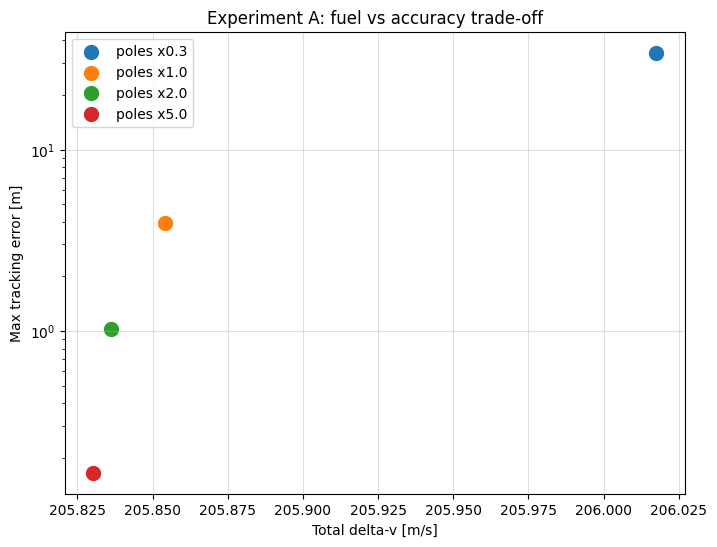

In [8]:
scales = [0.3, 1.0, 2.0, 5.0]
resultsA = {}
for s in scales:
    Ks = place_poles(A, B, desired_poles * s).gain_matrix
    resultsA[s] = run_sim(Ks, use_ff=True, T_end=T_rdv + 500)
    report(resultsA[s], f'poles x{s}')

# Fuel vs. accuracy trade-off scatter
plt.figure(figsize=(8, 6))
for s, r in resultsA.items():
    plt.scatter(r['dv'], r['max_err'], s=100, label=f'poles x{s}')
plt.xlabel('Total delta-v [m/s]'); plt.ylabel('Max tracking error [m]')
plt.yscale('log'); plt.title('Experiment A: fuel vs accuracy trade-off')
plt.legend(); plt.grid(True, alpha=0.4); plt.show()

# Experiment B: Damping Ratio Study

A standard second-order pole pair has the form

$$\lambda = -\zeta\omega_n \pm j\,\omega_n\sqrt{1-\zeta^2}$$

where:
- $\omega_n$ is the natural frequency (governs response *speed*),
- $\zeta$ is the damping ratio (governs *oscillation*):
  - small $\zeta$ (e.g. 0.3) → underdamped, overshoots and rings before settling,
  - $\zeta \to 1$ → critically damped, smooth non-oscillatory settling.

The nominal design in Part 3 used real poles only (equivalent to $\zeta = 1$). This experiment replaces them with **complex conjugate pairs** so the tracking error takes on genuine second-order character, and studies how $\zeta$ shapes the transient.

## Why it matters for rendezvous
Consider the chaser 10 m from a docking port. An underdamped error response means the chaser approaches, overshoots, comes back, overshoots again — exactly the behavior that leads to hardware damage on contact. Damping choice near a docking target is a hard safety constraint, not a tuning preference.

## Predictions (before simulation)
For $\zeta = 0.3$, $\omega_n = 0.02$ rad/s:
- Expected overshoot: $\%OS = 100\,e^{-\pi\zeta/\sqrt{1-\zeta^2}} \approx 37\%$
- Damped oscillation frequency: $\omega_d = \omega_n\sqrt{1-\zeta^2}$; period $2\pi/\omega_d \approx 329$ s

## Pole construction
The six-state system is treated as three second-order blocks in parallel:
- Poles 1–2: complex conjugate pair from $(\zeta, \omega_n)$
- Poles 3–4: complex conjugate pair from $(\zeta, 1.1\,\omega_n)$ — the slight frequency offset satisfies `place_poles`' distinctness requirement
- Poles 5–6: real poles near $-\omega_n$ (e.g. $-0.018$, $-0.022$)

Complex poles must appear in **conjugate pairs** ($a+jb$ and $a-jb$) — a physical system cannot have a lone complex eigenvalue.

Three cases are run: $\zeta = 0.3$ (underdamped), $\zeta = 0.7$ (typical control target), and $\zeta = 1.0$ (six distinct real poles near $-\omega_n$).

zeta = 0.3                          max_err=     1.04 m | final_err=   0.000 m | final_speed=0.0000 m/s | dV= 205.8 m/s | peak_u=0.1049
zeta = 0.7                          max_err=     1.01 m | final_err=   0.000 m | final_speed=0.0000 m/s | dV= 205.8 m/s | peak_u=0.1049
zeta = 1.0                          max_err=     1.06 m | final_err=   0.000 m | final_speed=0.0000 m/s | dV= 205.8 m/s | peak_u=0.1049


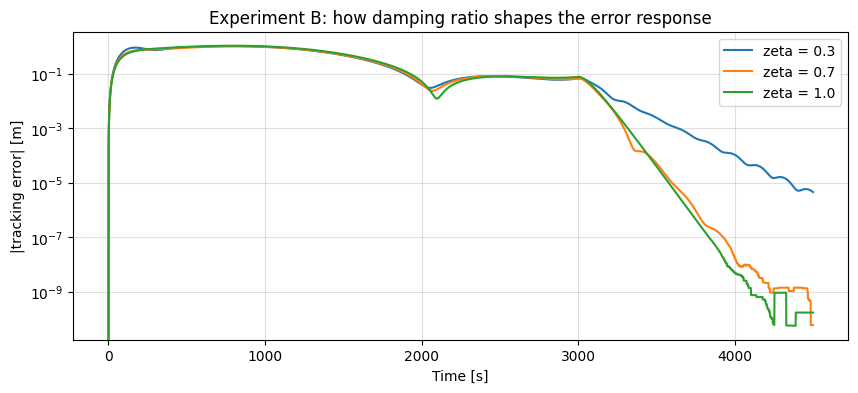

In [9]:
# ============================================================
# Experiment B: damping ratio study
# ============================================================
wn = 0.02   # natural frequency [rad/s] -- held fixed across cases

# ------------------------------------------------------------
# Analytic predictions for zeta = 0.3:
#   Overshoot           : 100 * exp(-pi*zeta / sqrt(1-zeta^2)) ~= 37.23 %
#   Oscillation period  : 2*pi / (wn * sqrt(1-zeta^2))        ~= 329.33 s
# ------------------------------------------------------------

# ------------------------------------------------------------
# Pole sets: two complex conjugate pairs (offset in wn for
# distinctness) plus two real poles.
# ------------------------------------------------------------
def complex_pair(zeta, wn):
    """Returns the two poles  -zeta*wn +/- j*wn*sqrt(1-zeta^2)."""
    real_part = -zeta * wn
    imag_part = wn * np.sqrt(1 - zeta**2)
    return [real_part + 1j*imag_part, real_part - 1j*imag_part]

pole_sets = {}

# Underdamped
pole_sets[0.3] = np.array( complex_pair(0.3, wn)
                         + complex_pair(0.3, 1.1*wn)
                         + [-0.018, -0.022] )

# Typical control target
pole_sets[0.7] = np.array( complex_pair(0.7, wn)
                         + complex_pair(0.7, 1.1*wn)
                         + [-0.018, -0.022] )

# Critically damped analog: six distinct real poles near -wn
pole_sets[1.0] = np.array([-0.018, -0.019, -0.020, -0.021, -0.022, -0.023])

# ------------------------------------------------------------
# Simulate each case
# ------------------------------------------------------------
resultsB = {}
for zeta, poles in pole_sets.items():
    Kb = place_poles(A, B, poles).gain_matrix
    resultsB[zeta] = run_sim(Kb, use_ff=True, T_end=T_rdv + 1500)
    report(resultsB[zeta], f'zeta = {zeta}')

# ------------------------------------------------------------
# Comparison plot: |tracking error| vs time, log scale
# ------------------------------------------------------------
plt.figure(figsize=(10, 4))
for zeta, r in resultsB.items():
    plt.semilogy(r['t'], np.linalg.norm(r['E'], axis=1), label=f'zeta = {zeta}')
plt.xlabel('Time [s]'); plt.ylabel('|tracking error| [m]')
plt.title('Experiment B: how damping ratio shapes the error response')
plt.legend(); plt.grid(True, which='both', alpha=0.4); plt.show()

# Animation

3D visualization of the closed-loop trajectory: the inertial frame shows both orbits around Earth (with the relative separation scaled up for visibility), and the LVLH frame shows the chaser approaching the target at the origin along the reference path.

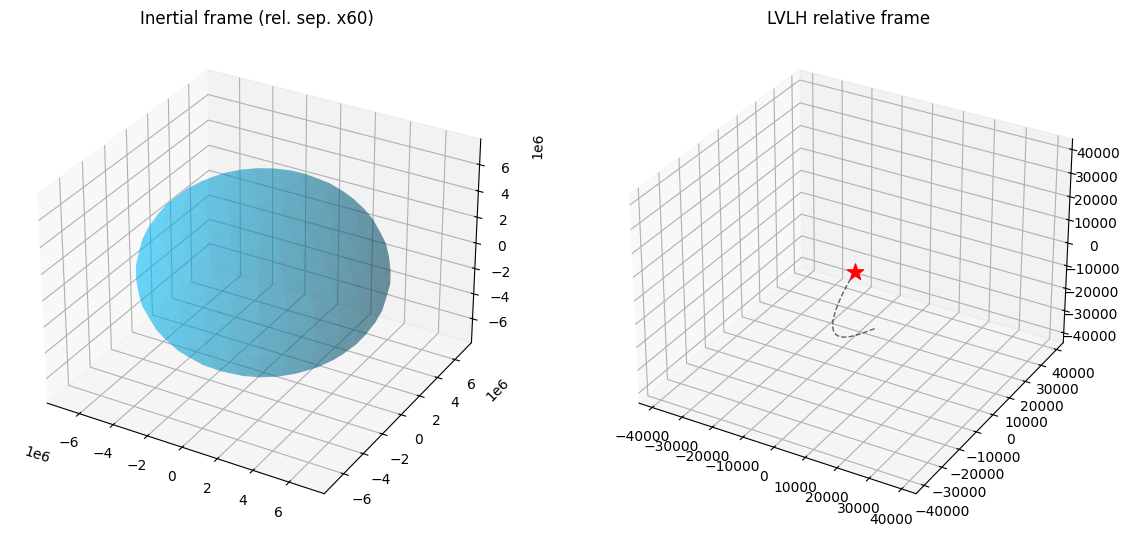

In [10]:
# Select which simulation result to animate
res_anim = res_nominal   # change to any result you want to animate
rho_h, Pd_h, Rt_h = res_anim['rho'], res_anim['Pd'], res_anim['Rt']
ts, Nn = res_anim['t'], len(res_anim['t'])

scale_vis = 60.0
Rc_vis = np.zeros((Nn, 3))
for k in range(Nn):
    k2, k1 = min(k+1, Nn-1), max(k-1, 0)
    v_t = (Rt_h[k2] - Rt_h[k1]) / (dt * (k2 - k1))
    R_e2l, _ = lvlh_frame(Rt_h[k], v_t)
    Rc_vis[k] = Rt_h[k] + scale_vis * (R_e2l.T @ rho_h[k])

idx = np.linspace(0, Nn-1, 120).astype(int)
fig = plt.figure(figsize=(14, 6.5))
ax1 = fig.add_subplot(121, projection='3d'); ax2 = fig.add_subplot(122, projection='3d')
u_s, v_s = np.mgrid[0:2*np.pi:30j, 0:np.pi:20j]
ax1.plot_surface(R_earth*np.cos(u_s)*np.sin(v_s), R_earth*np.sin(u_s)*np.sin(v_s),
                 R_earth*np.cos(v_s), color='deepskyblue', alpha=0.35)
lim1 = (R_earth + alt_c) * 1.15
ax1.set_xlim(-lim1, lim1); ax1.set_ylim(-lim1, lim1); ax1.set_zlim(-lim1, lim1)
ax1.set_title(f'Inertial frame (rel. sep. x{scale_vis:.0f})')
ax2.plot(Pd_h[:,0], Pd_h[:,1], Pd_h[:,2], 'k--', lw=1, alpha=0.6)
ax2.scatter(0, 0, 0, color='red', s=150, marker='*')
lim2 = np.abs(rho_h).max() * 1.1
ax2.set_xlim(-lim2, lim2); ax2.set_ylim(-lim2, lim2); ax2.set_zlim(-lim2, lim2)
ax2.set_title('LVLH relative frame')
tp, = ax1.plot([], [], [], 'r*', ms=12); cp, = ax1.plot([], [], [], 'go', ms=6)
ct, = ax1.plot([], [], [], 'g-', lw=1); cp2, = ax2.plot([], [], [], 'go', ms=8)
ct2, = ax2.plot([], [], [], 'g-', lw=1.2); ttl = fig.suptitle('')

def update(f):
    k = idx[f]
    tp.set_data([Rt_h[k,0]],[Rt_h[k,1]]); tp.set_3d_properties([Rt_h[k,2]])
    cp.set_data([Rc_vis[k,0]],[Rc_vis[k,1]]); cp.set_3d_properties([Rc_vis[k,2]])
    ct.set_data(Rc_vis[:k,0], Rc_vis[:k,1]); ct.set_3d_properties(Rc_vis[:k,2])
    cp2.set_data([rho_h[k,0]],[rho_h[k,1]]); cp